# Fase 3 — Modelo

Tudo neste notebook usa só treino e validação. A ordem importa: primeiro as métricas, porque cada decisão seguinte depende de medir.

In [1]:
import hashlib
import json
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.features import VetorizadorConteudo
from src.graficos import COR_EIXO, COR_PRINCIPAL, COR_SECUNDARIA, aplicar_estilo, eixo_br, numero_br, salvar
from src.traducoes import traduzir_token
from src.metricas import avaliar, comparar, erros_de_nota, intervalo, montar_protocolo
from src.recomendador import (
    Recomendador,
    afinidade_cidade,
    afinidade_distancia,
    ajustar_vies_usuarios,
    calcular_componentes,
    escolher_pesos,
    escolher_variante,
    escores_de_produto,
    grade_ao_redor,
    grade_de_pesos,
    modelo_ponderado,
    perfis_de_usuarios,
    similaridade_conteudo,
)
from src.recomendador import pontuar as pontuar_componentes

PASTA_PROCESSADOS = Path("data/processed")
PASTA_CONJUNTOS = PASTA_PROCESSADOS / "conjuntos"

aplicar_estilo()


def inteiro(valor):
    return f"{valor:,}".replace(",", ".")


locais = pd.read_parquet(PASTA_PROCESSADOS / "locais.parquet")
treino = pd.read_parquet(PASTA_CONJUNTOS / "treino.parquet")
validacao = pd.read_parquet(PASTA_CONJUNTOS / "validacao.parquet")
indice_locais = pd.read_parquet(PASTA_CONJUNTOS / "indice_locais.parquet").set_index("gmap_id")["linha"]
print(f"Treino: {inteiro(len(treino))}; validação: {inteiro(len(validacao))}")

Treino: 213.626; validação: 130.071


## Métricas e protocolo

Todas as métricas são as vistas em aula. As definições de cobertura, novidade e serendipidade vêm da literatura geral.

| Métrica | Papel | Como é medida |
|---|---|---|
| Taxa de conversão@10 (`conversao`) | Principal nos cenários 1 e 2 | Fração da lista que o usuário avaliou com nota 4 ou maior no período |
| Curva ROC: AUC de gosto (`auc_gosto`) | Principal nos cenários 1 e 2 | Entre os locais avaliados no período: nota 4 ou maior × nota 3 ou menor. Só usuários com os dois tipos; empate vale meio |
| Taxa de conversão, versão literal (`consumo`) | Reportada | Fração da lista que o usuário avaliou, com qualquer nota |
| Curva ROC: AUC de consumo (`auc_consumo`) | Principal no cenário 3 | Locais convertidos × demais candidatos |
| Correlação de rankings (`spearman`, `kendall`) | Confirmação | Spearman e tau-b de Kendall entre pontuação e nota, por usuário com 3 ou mais avaliações e notas variadas |
| MAE, MSE, RMSE | Só para a nota prevista | Previsão de nota contra a nota real |
| Cobertura do catálogo | Proteção contra listas repetidas | Fração dos candidatos em alguma lista |
| Cobertura dos espaços de usuários e de itens | Decisiva nos cenários 2 e 3 | Usuários com ao menos 10 locais pontuáveis; locais pontuáveis para ao menos 10 usuários |
| Novidade | Acompanhamento | Média de `−log2(fração das avaliações do local no treino)`; local sem avaliação conta como tendo uma |
| Serendipidade | Acompanhamento | Fração da lista que converte e não está na lista óbvia |
| Diversidade | Acompanhamento | Média de `1 − cosseno` entre os pares da lista |
| Intervalos de confiança | Em todas as comparações | 95%, *bootstrap* por usuário, semente 42, pareado nas diferenças; se inclui zero, é empate |

**Protocolo único**, com os mesmos usuários, candidatos e conversões para todo modelo:

- **Candidatos:** locais abertos do treino, ou uma lista informada (cenário 3).
- **Usuários:** do segmento, com ao menos uma conversão entre os candidatos; até 10.000, sorteados se passar disso.
- **Exclusão:** locais já avaliados no treino saem da lista do usuário.
- **Ordenação:** completa, sem amostrar negativos.
- **Empates:** desfeitos por sorteio com semente fixa, para não favorecer a ordem do catálogo.
- **Modelo:** uma função que devolve a matriz usuários × candidatos; `NaN` marca um par que ele não consegue pontuar.
- **Valores por usuário:** ficam disponíveis para os intervalos de confiança.

A célula abaixo confere o protocolo nos dados reais com duas referências simples, só na validação. Nenhuma decisão vem dela. Aqui a lista óbvia da serendipidade é a popularidade, apenas para exercitar o cálculo; a Fase 3 usa popularidade + local.

In [2]:
protocolo_antigo = montar_protocolo(treino, validacao, locais, ["antigo"])
linhas_vetores = indice_locais.loc[protocolo_antigo.candidatos]
vetorizador = VetorizadorConteudo().fit(locais[locais["gmap_id"].isin(treino["gmap_id"])])
vetores_candidatos = vetorizador.transform(locais.iloc[linhas_vetores])


def modelo_aleatorio(usuarios, candidatos):
    return np.random.default_rng(42).random((len(usuarios), len(candidatos)))


def modelo_popularidade(usuarios, candidatos):
    contagem = treino.groupby("gmap_id").size().reindex(candidatos, fill_value=0).to_numpy(dtype=float)
    return np.tile(contagem, (len(usuarios), 1))


print(f"Usuários no protocolo: {inteiro(len(protocolo_antigo.usuarios))}")
print(f"Candidatos: {inteiro(len(protocolo_antigo.candidatos))}")

resultados = {
    "Aleatória": avaliar(protocolo_antigo, modelo_aleatorio, completo=True, com_correlacao=True, vetores=vetores_candidatos, modelo_obvio=modelo_popularidade),
    "Popularidade": avaliar(protocolo_antigo, modelo_popularidade, completo=True, com_correlacao=True, vetores=vetores_candidatos, modelo_obvio=modelo_popularidade),
}
display(pd.DataFrame({nome: resultado.resumo() for nome, resultado in resultados.items()}).round(4))

convertidos_por_usuario = np.asarray((protocolo_antigo.notas >= 4).sum(axis=1)).ravel()
elegiveis = len(protocolo_antigo.candidatos) - np.asarray(protocolo_antigo.ja_avaliados.sum(axis=1)).ravel()
print(f"Conversão@10 esperada ao acaso: {numero_br((convertidos_por_usuario / elegiveis).mean(), 4)}")

for metrica in ["conversao", "auc_gosto", "auc_consumo"]:
    comparacao = comparar(resultados["Popularidade"], resultados["Aleatória"], metrica)
    situacao = "empate" if comparacao["empate"] else "diferença"
    print(f"Popularidade − aleatória em {metrica}: {numero_br(comparacao['diferenca'], 4)} "
          f"(IC 95%: {numero_br(comparacao['inferior'], 4)} a {numero_br(comparacao['superior'], 4)}; {situacao}; {inteiro(comparacao['usuarios'])} usuários)")

Usuários no protocolo: 6.078
Candidatos: 1.419


,Aleatória,Popularidade
conversao,0.0028,0.0204
consumo,0.0035,0.0229
auc_gosto,0.4973,0.4858
spearman,0.0050,-0.0294
kendall,0.0052,-0.0272
auc_consumo,0.5016,0.7394
novidade,11.6097,7.8146
diversidade,0.7616,0.6754
serendipidade,0.0027,0.0000
cobertura_catalogo,1.0000,0.0134


Conversão@10 esperada ao acaso: 0,0029
Popularidade − aleatória em conversao: 0,0175 (IC 95%: 0,0162 a 0,0188; diferença; 6.078 usuários)
Popularidade − aleatória em auc_gosto: -0,0115 (IC 95%: -0,0298 a 0,0071; empate; 2.397 usuários)
Popularidade − aleatória em auc_consumo: 0,2378 (IC 95%: 0,2309 a 0,2448; diferença; 6.078 usuários)


**Leitura:** a ordenação aleatória dá o que se espera do acaso: conversão@10 de 0,0028, contra 0,0029 calculados, e AUCs perto de 0,5. Isso indica que o protocolo não favorece nenhum modelo por construção. A popularidade converte mais (diferença de 0,0175, IC 95% de 0,0162 a 0,0188), mas empata com a aleatória na AUC de gosto (diferença de −0,0115, IC 95% de −0,0298 a 0,0071) e cobre só 1,3% do catálogo. Isso mostra por que a conversão sozinha não basta: ela mede aonde a pessoa vai, não se ela gostou.

**Limitação:** a AUC de gosto vale só para 2.397 dos 6.078 usuários, os que têm notas boas e ruins no período.

## Componentes do modelo

Conferência dos componentes nos dados reais, olhando só o treino. Nenhuma métrica é calculada aqui; a escolha entre as versões vem na seção seguinte.

- **Escore de qualidade:** `escore_i = (v_i·R_i + m·C) / (v_i + m)`, normalizado por `(escore − 1) / 4`. `C` é a média do treino e `m`, um percentil das avaliações por local. O `escore_cidade` usa como prior a média da cidade, suavizada pela mesma fórmula.
- **Perfil do usuário:** `p_u = Σ w_ui·x_i`, normalizado em L2, com `w_ui = nota − 3`. Só notas neutras: média simples dos vetores.
- **Popularidade:** `pop_i = log(1 + v_i) / log(1 + máx v)`. Local novo recebe a mediana da cidade, ou do catálogo.
- **Local:** fração das avaliações do usuário na cidade do candidato, ou média de `exp(−km/τ)` nos locais avaliados por ele.
- **Previsão de nota:** escore do local + viés regularizado do usuário (`reg = 10`), limitada a [1, 5].

In [3]:
escores, parametros = escores_de_produto(treino, locais)
nome_do_local = locais.set_index("gmap_id")["name"]
avaliados = escores[escores["avaliacoes"] > 0]
print(f"C (média do treino): {numero_br(parametros['C'], 3)}; m (mediana das avaliações por local): {numero_br(parametros['m'], 1)}")
print(f"Locais sem avaliação no treino: {inteiro((escores['avaliacoes'] == 0).sum())}, com escore {numero_br(parametros['C'], 3)}")

nota_cinco = avaliados[avaliados["media"] == 5]
print(f"Locais com média 5: {inteiro(len(nota_cinco))}; avaliações neles: mediana {numero_br(nota_cinco['avaliacoes'].median())}; "
      f"maior escore entre eles: {numero_br(nota_cinco['escore'].max(), 3)}")
colunas = ["nome", "cidade", "avaliacoes", "media", "escore", "popularidade", "posicao_na_cidade"]
tabela_escores = escores.assign(nome=nome_do_local)[colunas]
print("Abertos com maior escore:")
display(tabela_escores[escores["aberto"]].sort_values("escore", ascending=False).head(5).round(3).reset_index(drop=True))
print("Abertos com menor escore:")
display(tabela_escores[escores["aberto"]].sort_values("escore").head(5).round(3).reset_index(drop=True))

priores = escores.groupby("cidade")["prior_cidade"].first()
print(f"Prior das cidades: de {numero_br(priores.min(), 3)} a {numero_br(priores.max(), 3)}")
display(escores[["escore_normalizado", "escore_cidade", "popularidade"]].describe().round(3))
novos_treino = escores[escores["avaliacoes"] == 0]
print(f"Popularidade dos locais sem avaliação: mediana {numero_br(novos_treino['popularidade'].median(), 3)}; "
      f"dos avaliados: mediana {numero_br(avaliados['popularidade'].median(), 3)}")

vies_usuario = ajustar_vies_usuarios(treino, escores["escore"])
print(f"Viés dos usuários: de {numero_br(vies_usuario.min(), 3)} a {numero_br(vies_usuario.max(), 3)}; desvio-padrão {numero_br(vies_usuario.std(), 3)}")

C (média do treino): 4,116; m (mediana das avaliações por local): 75,0
Locais sem avaliação no treino: 216, com escore 4,116
Locais com média 5: 62; avaliações neles: mediana 3; maior escore entre eles: 4,413
Abertos com maior escore:


,nome,cidade,avaliacoes,media,escore,popularidade,posicao_na_cidade
0,Sweet Melissa,Laramie,424,4.788,4.687,0.838,1.0
1,Bar J Chuckwagon Suppers,Wilson,517,4.764,4.682,0.866,1.0
2,Sherrie's Place,Casper,315,4.787,4.658,0.797,1.0
3,Pizza Carrello,Gillette,522,4.709,4.634,0.867,1.0
4,Eggington's,Casper,698,4.670,4.617,0.907,2.0


Abertos com menor escore:


,nome,cidade,avaliacoes,media,escore,popularidade,posicao_na_cidade
0,Sonic Drive-In,Cheyenne,420,2.817,3.014,0.837,204.0
1,McDonald's,Douglas,425,2.981,3.151,0.838,30.0
2,Sonic Drive-In,Evansville,522,3.098,3.226,0.867,11.0
3,Sonic Drive-In,Cheyenne,451,3.109,3.252,0.847,203.0
4,McDonald's,Powell,276,3.018,3.253,0.779,24.0


Prior das cidades: de 3,546 a 4,554


,escore_normalizado,escore_cidade,popularidade
count,1863.000,1863.000,1863.000
mean,0.781,4.131,0.579
std,0.054,0.252,0.179
min,0.437,2.792,0.096
25%,0.763,4.007,0.471
50%,0.781,4.161,0.606
75%,0.812,4.295,0.697
max,0.922,4.737,1.000


Popularidade dos locais sem avaliação: mediana 0,620; dos avaliados: mediana 0,600
Viés dos usuários: de -1,382 a 0,793; desvio-padrão 0,151


In [4]:
inicio = perf_counter()
vetores_todos = vetorizador.transform(locais)
posicao_do_local = indice_locais.to_dict()
perfis, usuarios_perfil = perfis_de_usuarios(treino, vetores_todos, posicao_do_local)
linha_do_perfil = pd.Series(np.arange(len(usuarios_perfil)), index=usuarios_perfil)
usuarios_protocolo, candidatos_protocolo = protocolo_antigo.usuarios, protocolo_antigo.candidatos
sims = similaridade_conteudo(perfis[linha_do_perfil.loc[usuarios_protocolo].to_numpy()], vetores_candidatos)
tempo_conteudo = perf_counter() - inicio

inicio = perf_counter()
por_cidade = afinidade_cidade(treino, locais, usuarios_protocolo, candidatos_protocolo)
tempo_cidade = perf_counter() - inicio

inicio = perf_counter()
por_distancia = afinidade_distancia(treino, locais, usuarios_protocolo, candidatos_protocolo, tau=25)
tempo_distancia = perf_counter() - inicio

normas_perfil = np.sqrt(np.asarray(perfis.multiply(perfis).sum(axis=1)).ravel())
so_neutras = treino.groupby("user_id")["rating"].agg(lambda notas: (notas == 3).all())

componentes = pd.DataFrame(
    {
        "similaridade de conteúdo": sims.ravel(),
        "local por cidade": por_cidade.ravel(),
        "local por distância (τ = 25 km)": por_distancia.ravel(),
    }
)
print(f"Perfis: {inteiro(len(usuarios_perfil))}; só com notas neutras: {inteiro(so_neutras.sum())}; "
      f"com vetor nulo: {inteiro((normas_perfil == 0).sum())}")
print(f"Tempo para {inteiro(len(usuarios_protocolo))} usuários × {inteiro(len(candidatos_protocolo))} candidatos: "
      f"conteúdo {numero_br(tempo_conteudo, 1)} s; cidade {numero_br(tempo_cidade, 1)} s; distância {numero_br(tempo_distancia, 1)} s")
display(componentes.describe().round(3))
print(f"Correlação entre local por cidade e por distância: {numero_br(np.corrcoef(por_cidade.ravel(), por_distancia.ravel())[0, 1], 3)}")

Perfis: 95.365; só com notas neutras: 5.384; com vetor nulo: 5
Tempo para 6.078 usuários × 1.419 candidatos: conteúdo 0,6 s; cidade 0,2 s; distância 0,3 s


,similaridade de conteúdo,local por cidade,local por distância (τ = 25 km)
count,8624682.000,8624682.000,8624682.000
mean,0.663,0.069,0.072
std,0.095,0.220,0.206
min,-0.000,0.000,0.000
25%,0.613,0.000,0.000
50%,0.672,0.000,0.000
75%,0.725,0.000,0.004
max,1.000,1.000,0.999


Correlação entre local por cidade e por distância: 0,958


**Leitura:**

- **A suavização funciona:** os 62 locais com média 5 têm mediana de 3 avaliações, e nenhum passa de um escore de 4,413. O maior escore entre os abertos é 4,687 (Sweet Melissa, média de 4,788 em 424 avaliações). Os menores são redes de fast food com centenas de avaliações, o que confirma que popular não é sinônimo de bom.
- **Local novo não é penalizado:** a popularidade dos locais sem avaliação (mediana de 0,620) fica perto da dos avaliados (0,600).
- **Perfis:** dos 95.365 perfis, 5.384 são só de notas neutras e 5 têm vetor nulo, que resulta em similaridade neutra.
- **Cidade e distância são muito parecidas:** a correlação é de 0,958 com τ = 25 km, então a comparação da próxima etapa pode terminar em empate.
- **Velocidade:** os componentes levam cerca de um segundo para 6.078 usuários, o que torna viável a grade de pesos.

**Atenção ao ler os pesos:** os componentes têm espalhamentos muito diferentes. O desvio-padrão é de 0,054 no escore normalizado, 0,095 na similaridade, 0,179 na popularidade e 0,220 no local por cidade. Um peso maior não significa maior importância: o escore precisa de um peso alto para mudar a ordem tanto quanto o local muda com um peso baixo. Os pesos devem ser lidos pelo efeito nas métricas.

## Pontuação e escolha dos hiperparâmetros (cenário 1)

`s(u,i) = α·sim(u,i) + β·escore_i + γ·local_u(i) + δ·pop_i`, com `sim = (cos + 1) / 2`, pesos não negativos e soma 1.

**Critério, decidido pela usuária:** entre as combinações com conversão@10 de pelo menos 95% da melhor, a de maior AUC de gosto. Exige-se `α ≥ 0,1`, porque a técnica é baseada em conteúdo; o melhor com `α = 0` aparece à parte. A cobertura é sempre reportada.

**Regra para variantes (local, `m`, centro, blocos):** aplica-se o mesmo critério, e a configuração atual só muda se a melhora na AUC de gosto não for empate. Tudo é medido na validação, com o protocolo acima. As grades ficam em `modelos/grades/`; com `REAPROVEITAR = True`, são lidas do arquivo em vez de recalculadas.

In [5]:
PASTA_GRADES = Path("modelos/grades")
PASTA_GRADES.mkdir(parents=True, exist_ok=True)
REAPROVEITAR = True
PESOS_REFERENCIA = (0.1, 0.2, 0.5, 0.2)
NOMES_PESOS = ["alfa", "beta", "gama", "delta"]


def compor(**opcoes):
    return calcular_componentes(treino, locais, protocolo_antigo.usuarios, protocolo_antigo.candidatos, **opcoes)


def avaliar_grade(nome, protocolo, componentes, combinacoes, config):
    # O nome do arquivo inclui a configuração, para nunca reaproveitar a grade de outra.
    chave = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:10]
    caminho = PASTA_GRADES / f"{nome}_{chave}.csv"
    if REAPROVEITAR and caminho.exists():
        return pd.read_csv(caminho)
    linhas = []
    for pesos in combinacoes:
        resumo = avaliar(protocolo, modelo_ponderado(componentes, pesos)).resumo()
        linhas.append(dict(zip(NOMES_PESOS, pesos)) | resumo[["conversao", "consumo", "auc_gosto", "cobertura_catalogo"]].to_dict())
    grade = pd.DataFrame(linhas)
    grade.to_csv(caminho, index=False)
    return grade


def texto_ic(comparacao, casas=4):
    marca = " (empate)" if comparacao["empate"] else ""
    return f"{numero_br(comparacao['diferenca'], casas)} [{numero_br(comparacao['inferior'], casas)}; {numero_br(comparacao['superior'], casas)}]{marca}"


def tabela_contra_base(resultados, base):
    linhas = {}
    for nome, resultado in resultados.items():
        resumo = resultado.resumo()
        linhas[nome] = {
            "conversão@10": round(resumo["conversao"], 4),
            "AUC de gosto": round(resumo["auc_gosto"], 4),
            "cobertura do catálogo": round(resumo["cobertura_catalogo"], 3),
            f"conversão − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "conversao")),
            f"gosto − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "auc_gosto")),
        }
    return pd.DataFrame(linhas).T


def medir(componentes, pesos, **opcoes):
    return avaliar(protocolo_antigo, modelo_ponderado(componentes, pesos), **opcoes)


pd.set_option("display.width", 220, "display.max_colwidth", 60, "display.max_columns", 30)
print(f"Protocolo: {inteiro(len(protocolo_antigo.usuarios))} usuários antigos × {inteiro(len(protocolo_antigo.candidatos))} candidatos")

Protocolo: 6.078 usuários antigos × 1.419 candidatos


### Etapa 1: local

Com os pesos de referência 0,1 / 0,2 / 0,5 / 0,2 (conteúdo / escore / local / popularidade), comparam-se a cidade, a distância e a média das duas.

**Por que esta etapa não decide sozinha:** com pesos fixos, um τ maior achata o componente de local e dá mais força relativa ao escore, um efeito que os próprios pesos também produzem. Nessa comparação, o critério continua preferindo τ maior a cada valor testado. Por isso, a tabela abaixo é só orientação, e a escolha do local é feita junto com os pesos, na etapa 2.

In [6]:
opcoes_local = {"cidade": {"local": "cidade"}}
for tau in [10, 25, 50, 100, 200, 400]:
    opcoes_local[f"distância τ={tau}"] = {"local": "distancia", "tau": tau}
    opcoes_local[f"média τ={tau}"] = {"local": "media", "tau": tau}

resultados_local = {nome: medir(compor(**opcoes), PESOS_REFERENCIA) for nome, opcoes in opcoes_local.items()}
display(tabela_contra_base(resultados_local, "cidade"))
print(f"Com os pesos de referência, o critério apontaria: {escolher_variante(resultados_local, 'cidade', comparar)}")

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − cidade,gosto − cidade
cidade,0.0744,0.5527,0.499,,
distância τ=10,0.0726,0.5495,0.61,"-0,0018 [-0,0034; -0,0003]","-0,0032 [-0,0126; 0,0061] (empate)"
média τ=10,0.0747,0.5509,0.563,"0,0003 [-0,0010; 0,0015] (empate)","-0,0018 [-0,0089; 0,0054] (empate)"
distância τ=25,0.0755,0.5563,0.554,"0,0011 [-0,0002; 0,0023] (empate)","0,0037 [-0,0047; 0,0118] (empate)"
média τ=25,0.0758,0.5523,0.522,"0,0014 [0,0004; 0,0023]","-0,0004 [-0,0057; 0,0049] (empate)"
distância τ=50,0.0765,0.5594,0.514,"0,0021 [0,0010; 0,0032]","0,0068 [-0,0004; 0,0139] (empate)"
média τ=50,0.076,0.553,0.506,"0,0016 [0,0008; 0,0024]","0,0003 [-0,0044; 0,0049] (empate)"
distância τ=100,0.077,0.5613,0.483,"0,0026 [0,0015; 0,0036]","0,0086 [0,0019; 0,0153]"
média τ=100,0.0755,0.5526,0.504,"0,0011 [0,0003; 0,0017]","-0,0000 [-0,0044; 0,0042] (empate)"
distância τ=200,0.0759,0.5634,0.45,"0,0015 [0,0005; 0,0025]","0,0107 [0,0038; 0,0176]"


Com os pesos de referência, o critério apontaria: distância τ=400


**Leitura:** com os pesos fixos, a conversão atinge o máximo em τ = 100 km (0,0770), mas a AUC de gosto continua subindo até τ = 400 km (0,5672), enquanto a cobertura do catálogo cai para 37,8%. Um τ muito grande achata o local, o que favorece o escore. Por isso esta tabela não decide.

### Etapa 2: local e pesos em conjunto

Grade com passo de 0,1 (286 combinações, na ordem conteúdo / escore / local / popularidade) para cada versão de local. O critério se aplica ao conjunto todo. Em caso de empate com a melhor combinação usando cidade, fica a cidade, mais simples de explicar.

In [7]:
versoes_local = {"cidade": {"local": "cidade"}}
for tau in [50, 100, 200, 400, 800]:
    versoes_local[f"distância τ={tau}"] = {"local": "distancia", "tau": tau}
grades_por_local = {
    nome: avaliar_grade("etapa2_pesos", protocolo_antigo, compor(**opcoes), grade_de_pesos(0.1), opcoes)
    for nome, opcoes in versoes_local.items()
}
unida = pd.concat([grade_local.assign(versao=nome) for nome, grade_local in grades_por_local.items()], ignore_index=True)
melhor_geral = unida.loc[unida["alfa"] >= 0.1 - 1e-9, "conversao"].max()
limite_conversao = 0.95 * melhor_geral
linhas_versao = []
for nome, grade_local in grades_por_local.items():
    aptas_versao = grade_local[(grade_local["alfa"] >= 0.1 - 1e-9) & (grade_local["conversao"] >= limite_conversao)]
    if aptas_versao.empty:
        linhas_versao.append({"versão": nome, "aptas": 0})
        continue
    melhor = aptas_versao.sort_values(["auc_gosto", "conversao"], ascending=False).iloc[0]
    linhas_versao.append({"versão": nome, "aptas": len(aptas_versao)} | melhor[NOMES_PESOS + ["conversao", "auc_gosto", "cobertura_catalogo"]].astype(float).to_dict())
tabela_versoes = pd.DataFrame(linhas_versao)
print(f"Melhor conversão no conjunto (α ≥ 0,1): {numero_br(melhor_geral, 4)}; limite de 95%: {numero_br(limite_conversao, 4)}")
display(tabela_versoes.round(4))

vencedora_conjunta = escolher_pesos(unida)
versao_escolhida = vencedora_conjunta["versao"]
pesos_vencedora = tuple(float(vencedora_conjunta[nome]) for nome in NOMES_PESOS)
if versao_escolhida != "cidade":
    linha_cidade = tabela_versoes[tabela_versoes["versão"] == "cidade"].iloc[0]
    if linha_cidade["aptas"] > 0:
        pesos_cidade = tuple(float(linha_cidade[nome]) for nome in NOMES_PESOS)
        com_cidade = medir(compor(local="cidade"), pesos_cidade)
        com_vencedora = medir(compor(**versoes_local[versao_escolhida]), pesos_vencedora)
        comparacoes = {metrica: comparar(com_vencedora, com_cidade, metrica) for metrica in ["conversao", "auc_gosto"]}
        print(f"{versao_escolhida} − cidade: conversão {texto_ic(comparacoes['conversao'])}; gosto {texto_ic(comparacoes['auc_gosto'])}")
        if comparacoes["auc_gosto"]["empate"] and comparacoes["conversao"]["empate"]:
            versao_escolhida, pesos_vencedora = "cidade", pesos_cidade
print(f"Versão de local escolhida: {versao_escolhida}")

configuracao = dict(versoes_local[versao_escolhida])
componentes_base = compor(**configuracao)
grade = grades_por_local[versao_escolhida]
escolha = grade[grade[NOMES_PESOS].sub(list(pesos_vencedora)).abs().sum(axis=1) < 1e-9].iloc[0]
pesos_escolhidos = pesos_vencedora

elegiveis = grade[grade["alfa"] >= 0.1 - 1e-9]
melhor_conversao = elegiveis.sort_values("conversao", ascending=False).iloc[0]
melhor_sem_conteudo = grade[grade["alfa"] == 0].pipe(escolher_pesos, alfa_minimo=0)
aptas = elegiveis[elegiveis["conversao"] >= 0.95 * melhor_conversao["conversao"]]
print(f"Combinações: {len(grade)}; com α ≥ 0,1: {len(elegiveis)}; aptas: {len(aptas)}")
print(f"Pesos escolhidos (α, β, γ, δ): {pesos_escolhidos}")
colunas_grade = NOMES_PESOS + ["conversao", "consumo", "auc_gosto", "cobertura_catalogo"]
display(
    pd.DataFrame(
        {"escolhida": escolha, "melhor conversão (α ≥ 0,1)": melhor_conversao, "melhor com α = 0": melhor_sem_conteudo}
    ).T[colunas_grade].astype(float).round(4)
)
print("Aptas com maior AUC de gosto:")
display(aptas.sort_values("auc_gosto", ascending=False).head(8)[colunas_grade].round(4))

pesos_melhor_conversao = tuple(float(melhor_conversao[nome]) for nome in NOMES_PESOS)
pesos_sem_conteudo = tuple(float(melhor_sem_conteudo[nome]) for nome in NOMES_PESOS)
resultados_pesos = {
    "escolhida": medir(componentes_base, pesos_escolhidos),
    "melhor conversão": medir(componentes_base, pesos_melhor_conversao),
    "melhor com α = 0": medir(componentes_base, pesos_sem_conteudo),
    "referência": medir(componentes_base, PESOS_REFERENCIA),
}
display(tabela_contra_base(resultados_pesos, "escolhida"))

Melhor conversão no conjunto (α ≥ 0,1): 0,0793; limite de 95%: 0,0754


,versão,aptas,alfa,beta,gama,delta,conversao,auc_gosto,cobertura_catalogo
0,cidade,2,0.1,0.1,0.6,0.2,0.0761,0.5168,0.5116
1,distância τ=50,21,0.1,0.2,0.5,0.2,0.0765,0.5594,0.5144
2,distância τ=100,20,0.1,0.2,0.5,0.2,0.0770,0.5613,0.4834
3,distância τ=200,10,0.1,0.2,0.5,0.2,0.0759,0.5634,0.4503
4,distância τ=400,5,0.1,0.1,0.7,0.1,0.0770,0.5539,0.5659
5,distância τ=800,1,0.1,0.0,0.8,0.1,0.0755,0.4727,0.5779


distância τ=200 − cidade: conversão -0,0001 [-0,0014; 0,0011] (empate); gosto 0,0466 [0,0381; 0,0556]
Versão de local escolhida: distância τ=200


Combinações: 286; com α ≥ 0,1: 220; aptas: 14
Pesos escolhidos (α, β, γ, δ): (0.1, 0.2, 0.5, 0.2)


,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
escolhida,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503
"melhor conversão (α ≥ 0,1)",0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764
melhor com α = 0,0.0,0.2,0.6,0.2,0.0762,0.0874,0.5722,0.4285


Aptas com maior AUC de gosto:


,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
90,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503
142,0.2,0.2,0.4,0.2,0.0753,0.0866,0.5590,0.5264
83,0.1,0.1,0.7,0.1,0.0775,0.0894,0.5511,0.6004
89,0.1,0.2,0.4,0.3,0.0752,0.0864,0.5477,0.3686
136,0.2,0.1,0.6,0.1,0.0752,0.0878,0.5341,0.7456
82,0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764
135,0.2,0.1,0.5,0.2,0.0781,0.0920,0.5224,0.5666
81,0.1,0.1,0.5,0.3,0.0769,0.0906,0.5122,0.4024


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − escolhida,gosto − escolhida
escolhida,0.0759,0.5634,0.45,,
melhor conversão,0.079,0.5229,0.476,"0,0031 [0,0021; 0,0041]","-0,0404 [-0,0468; -0,0347]"
melhor com α = 0,0.0762,0.5722,0.428,"0,0003 [-0,0006; 0,0012] (empate)","0,0089 [0,0035; 0,0144]"
referência,0.0759,0.5634,0.45,"0,0000 [0,0000; 0,0000] (empate)","0,0000 [0,0000; 0,0000] (empate)"


**Escolha conjunta:** a melhor conversão do conjunto é 0,0793, o que dá um limite de 0,0754. O critério escolhe **distância com τ = 200 km e pesos 0,1 / 0,2 / 0,5 / 0,2** (conversão de 0,0759 e AUC de gosto de 0,5634). O intervalo ficou fechado: em τ = 800 km, só uma combinação passa do limite, com AUC de 0,4727. Contra a melhor combinação com cidade, a conversão empata (−0,0001, IC 95% de −0,0014 a 0,0011) e a AUC de gosto é maior (0,0466, IC 95% de 0,0381 a 0,0556), então a distância não é empate e fica.

Os pesos coincidem com os de referência, mas saíram da grade, não foram fixados. O melhor com `α = 0` (0 / 0,2 / 0,6 / 0,2) empata na conversão (0,0003, IC 95% de −0,0006 a 0,0012) e tem AUC de gosto maior (0,0089, IC 95% de 0,0035 a 0,0144): a exigência de `α ≥ 0,1` tem custo.

In [8]:
limiares_fronteira = [1.0, 0.97, 0.95, 0.9, 0.85, 0.8, 0.7]
fronteira = []
for limiar in limiares_fronteira:
    combinacao = escolher_pesos(grade, limiar=limiar)
    fronteira.append({"limiar de conversão": limiar} | combinacao[colunas_grade].astype(float).to_dict())
fronteira = pd.DataFrame(fronteira)
fronteira["conversão cedida"] = 1 - fronteira["conversao"] / melhor_conversao["conversao"]
fronteira["gosto ganho"] = fronteira["auc_gosto"] - melhor_conversao["auc_gosto"]
display(fronteira.round(4))

correlacao_grade = elegiveis["conversao"].corr(elegiveis["auc_gosto"])
print(f"Correlação entre conversão e AUC de gosto na grade: {numero_br(correlacao_grade, 2)}")

,limiar de conversão,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo,conversão cedida,gosto ganho
0,1.00,0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764,0.0000,0.0000
1,0.97,0.1,0.1,0.7,0.1,0.0775,0.0894,0.5511,0.6004,0.0192,0.0281
2,0.95,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503,0.0391,0.0404
3,0.90,0.1,0.3,0.4,0.2,0.0736,0.0828,0.5960,0.3925,0.0689,0.0730
4,0.85,0.1,0.4,0.3,0.2,0.0693,0.0770,0.6193,0.3305,0.1230,0.0963
5,0.80,0.1,0.4,0.4,0.1,0.0663,0.0734,0.6377,0.4257,0.1615,0.1148
6,0.70,0.1,0.6,0.2,0.1,0.0567,0.0619,0.6737,0.2727,0.2829,0.1507


Correlação entre conversão e AUC de gosto na grade: -0,22


**Fronteira antes dos refinamentos:** nesta grade, ceder 3,9% da melhor conversão rende 0,0404 de AUC de gosto, e ceder 16,2% rende 0,1148, com a cobertura caindo de 47,6% para 42,6%. A figura `31_grade_pesos` e a fronteira da configuração final estão na seção de sensibilidade.

### Etapa 3: refinamentos, um por vez

Cada refinamento parte da configuração atual, com os pesos da etapa 2. A última tabela mede o quanto se abre mão ao deixar fora os atributos derivados e o preço, sem adotar nada.

In [9]:
variantes_etapa3 = {
    "percentil de m": {"p50": {"percentil": 50}, "p25": {"percentil": 25}, "p75": {"percentil": 75}},
    "centro do perfil": {"3": {"centro": "fixo"}, "média do usuário": {"centro": "usuario"}},
    "blocos do vetor": {
        "categorias + atributos": {"opcoes_vetor": {}},
        "categorias + atributos × 0,5": {"opcoes_vetor": {"peso_atributos": 0.5}},
        "só categorias": {"opcoes_vetor": {"peso_atributos": 0}},
        "só atributos": {"opcoes_vetor": {"peso_categorias": 0}},
    },
}
registro_etapa3 = {}
for tema, opcoes_tema in variantes_etapa3.items():
    base_tema = next(iter(opcoes_tema))
    resultados_tema = {nome: medir(compor(**(configuracao | opcoes)), pesos_escolhidos) for nome, opcoes in opcoes_tema.items()}
    print(f"{tema}:")
    display(tabela_contra_base(resultados_tema, base_tema))
    vencedora = escolher_variante(resultados_tema, base_tema, comparar)
    registro_etapa3[tema] = vencedora
    configuracao |= opcoes_tema[vencedora]
    print(f"Fica: {vencedora}")
print("Configuração depois da etapa 3:", configuracao)

componentes_atuais = compor(**configuracao)
# A conferência liga sempre o bloco de atributos; do contrário, derivados e preço não teriam efeito.
conferencia = {
    "categorias + declaráveis": medir(compor(**(configuracao | {"opcoes_vetor": {}})), pesos_escolhidos),
    "com atributos derivados": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_derivados": True}})), pesos_escolhidos),
    "com preço": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_preco": True}})), pesos_escolhidos),
    "com derivados e preço": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_derivados": True, "incluir_preco": True}})), pesos_escolhidos),
}
print("Conferência das exclusões (só para medir):")
display(tabela_contra_base(conferencia, "categorias + declaráveis"))

percentil de m:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − p50,gosto − p50
p50,0.0759,0.5634,0.45,,
p25,0.0748,0.5752,0.442,"-0,0011 [-0,0017; -0,0006]","0,0118 [0,0089; 0,0149]"
p75,0.0771,0.5476,0.451,"0,0011 [0,0005; 0,0017]","-0,0158 [-0,0195; -0,0122]"


Fica: p25


centro do perfil:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − 3,gosto − 3
3,0.0748,0.5752,0.442,,
média do usuário,0.0739,0.585,0.459,"-0,0009 [-0,0018; -0,0000]","0,0097 [0,0049; 0,0145]"


Fica: média do usuário


blocos do vetor:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − categorias + atributos,gosto − categorias + atributos
categorias + atributos,0.0739,0.585,0.459,,
"categorias + atributos × 0,5",0.0737,0.5872,0.471,"-0,0002 [-0,0008; 0,0004] (empate)","0,0022 [-0,0009; 0,0055] (empate)"
só categorias,0.0737,0.5868,0.483,"-0,0003 [-0,0011; 0,0005] (empate)","0,0018 [-0,0021; 0,0058] (empate)"
só atributos,0.0722,0.5814,0.483,"-0,0017 [-0,0026; -0,0008]","-0,0035 [-0,0087; 0,0014] (empate)"


Fica: categorias + atributos
Configuração depois da etapa 3: {'local': 'distancia', 'tau': 200, 'percentil': 25, 'centro': 'usuario', 'opcoes_vetor': {}}


Conferência das exclusões (só para medir):


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − categorias + declaráveis,gosto − categorias + declaráveis
categorias + declaráveis,0.0739,0.585,0.459,,
com atributos derivados,0.0744,0.5891,0.452,"0,0005 [-0,0002; 0,0011] (empate)","0,0042 [0,0008; 0,0076]"
com preço,0.074,0.586,0.459,"0,0000 [-0,0004; 0,0005] (empate)","0,0010 [-0,0010; 0,0032] (empate)"
com derivados e preço,0.0746,0.5885,0.454,"0,0007 [0,0000; 0,0013]","0,0035 [-0,0000; 0,0070] (empate)"


**Decisões da etapa 3:**

- **`m` no percentil 25 (m = 26):** a AUC de gosto sobe 0,0118 (IC 95% de 0,0089 a 0,0149) e a conversão cai 0,0011, dentro do limite.
- **Centro pela média do usuário:** a AUC de gosto sobe 0,0097 (IC 95% de 0,0049 a 0,0145) e a conversão cai 0,0009. Quem não varia as notas continua com centro 3.
- **Blocos:** categorias + atributos ficam, pois as alternativas úteis empatam. "Só categorias" tem cobertura um pouco maior (48,3% × 45,9%) sem diferença nas duas métricas principais; "só atributos" converte menos.
- **Exclusões:** os atributos derivados rendem 0,0042 de AUC de gosto (IC 95% de 0,0008 a 0,0076) e empatam na conversão. O preço empata nas duas. O ganho é pequeno, então continuam fora: não é a diferença grande que levaria a rever a decisão.

### Etapa 4: refino dos pesos

Só roda se a etapa 3 mudou algo: pesos em torno do escolhido (±0,1, passo de 0,05). Depois disso, a configuração do cenário 1 fica congelada.

In [10]:
mudou_etapa3 = any(registro_etapa3[tema] != next(iter(variantes_etapa3[tema])) for tema in variantes_etapa3)
if mudou_etapa3:
    grade_refino = avaliar_grade("etapa4_refino", protocolo_antigo, componentes_atuais, grade_ao_redor(pesos_escolhidos), configuracao)
    pesos_finais = tuple(float(escolher_pesos(grade_refino)[nome]) for nome in NOMES_PESOS)
    print(f"Refino com {len(grade_refino)} combinações: {pesos_finais}")
else:
    pesos_finais = pesos_escolhidos
    print("A etapa 3 não mudou nada; a etapa 4 não é necessária.")

congelado = {"pesos": dict(zip(NOMES_PESOS, pesos_finais)), "configuracao": configuracao}
Path("modelos/cenario1.json").write_text(json.dumps(congelado, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(congelado, ensure_ascii=False))
resultado_final = medir(componentes_atuais, pesos_finais)
print(resultado_final.resumo().round(4).to_dict())
for metrica, rotulo in [("conversao", "Conversão@10"), ("auc_gosto", "AUC de gosto")]:
    media, inferior, superior = intervalo(resultado_final, metrica)
    print(f"{rotulo}: {numero_br(media, 4)} (IC 95%: {numero_br(inferior, 4)} a {numero_br(superior, 4)})")
print(f"Usuários com AUC de gosto: {inteiro(resultado_final.por_usuario['auc_gosto'].notna().sum())}")
parametros_finais = escores_de_produto(treino, locais, configuracao["percentil"])[1]
print(f"m com o percentil {configuracao['percentil']}: {numero_br(parametros_finais['m'], 1)}")

Refino com 52 combinações: (0.1, 0.2, 0.5, 0.2)
{"pesos": {"alfa": 0.1, "beta": 0.2, "gama": 0.5, "delta": 0.2}, "configuracao": {"local": "distancia", "tau": 200, "percentil": 25, "centro": "usuario", "opcoes_vetor": {}}}


{'conversao': 0.0739, 'consumo': 0.0836, 'auc_gosto': 0.585, 'cobertura_catalogo': 0.4595, 'cobertura_usuarios': 1.0, 'cobertura_itens': 1.0}
Conversão@10: 0,0739 (IC 95%: 0,0713 a 0,0766)
AUC de gosto: 0,5850 (IC 95%: 0,5721 a 0,5981)
Usuários com AUC de gosto: 2.397
m com o percentil 25: 26,0


**Congelado para o cenário 1:** distância com τ = 200 km, `m` no percentil 25, centro pela média do usuário, categorias + atributos e pesos 0,1 / 0,2 / 0,5 / 0,2, gravados em `modelos/cenario1.json`. O refino com 52 combinações não mudou os pesos. Na validação: **conversão@10 de 0,0739 (IC 95% de 0,0713 a 0,0766) e AUC de gosto de 0,5850 (IC 95% de 0,5721 a 0,5981)**, esta medida em 2.397 usuários.

### Conferência: cidade × distância com os pesos refinados

A etapa 1 comparou as versões de local com os pesos de referência. Aqui a comparação se repete com a configuração e os pesos finais. Pela regra do plano, em caso de empate ou se a distância não ganhar, fica a cidade.

In [11]:
config_sem_local = {chave: valor for chave, valor in configuracao.items() if chave not in {"local", "tau"}}
final_local = {"cidade": medir(compor(**(config_sem_local | {"local": "cidade"})), pesos_finais)}
for tau in [50, 100, 200, 400, 800]:
    final_local[f"distância τ={tau}"] = medir(compor(**(config_sem_local | {"local": "distancia", "tau": tau})), pesos_finais)
display(tabela_contra_base(final_local, "cidade"))
local_final = escolher_variante(final_local, "cidade", comparar)
print(f"Local pelo critério com os pesos finais: {local_final}")
print(f"Local congelado: {configuracao['local']}, τ = {configuracao.get('tau')}")

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − cidade,gosto − cidade
cidade,0.0713,0.5717,0.514,,
distância τ=50,0.0737,0.5755,0.524,"0,0023 [0,0011; 0,0034]","0,0037 [-0,0039; 0,0107] (empate)"
distância τ=100,0.0741,0.5802,0.495,"0,0027 [0,0017; 0,0037]","0,0084 [0,0015; 0,0152]"
distância τ=200,0.0739,0.585,0.459,"0,0026 [0,0016; 0,0036]","0,0132 [0,0064; 0,0199]"
distância τ=400,0.0716,0.5913,0.395,"0,0002 [-0,0008; 0,0013] (empate)","0,0196 [0,0121; 0,0269]"
distância τ=800,0.0664,0.6051,0.301,"-0,0049 [-0,0061; -0,0037]","0,0334 [0,0255; 0,0416]"


Local pelo critério com os pesos finais: distância τ=400
Local congelado: distancia, τ = 200


**Leitura:** com a configuração final, a distância com τ = 200 km ganha da cidade na conversão (0,0026, IC 95% de 0,0016 a 0,0036) e na AUC de gosto (0,0132, IC 95% de 0,0064 a 0,0199), então a regra de voltar para a cidade não se aplica.

Comparando só os valores de τ com pesos fixos, o critério apontaria τ = 400 km (conversão de 0,0716, AUC de 0,5913 e cobertura de 39,5%). **Mantém-se τ = 200 km**, porque essa comparação tem o mesmo problema da etapa 1, e a escolha conjunta é a mais confiável. A ressalva é que a escolha conjunta foi feita antes dos refinamentos de `m` e centro.

### Ablação

Cada componente sozinho e o modelo sem cada um (com os demais pesos reescalados para somar 1), comparados com o modelo escolhido.

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − modelo escolhido,gosto − modelo escolhido
modelo escolhido,0.0739,0.585,0.459,,
só conteúdo,0.0041,0.5321,0.994,"-0,0698 [-0,0724; -0,0672]","-0,0528 [-0,0701; -0,0352]"
só escore,0.0031,0.7136,0.01,"-0,0708 [-0,0734; -0,0682]","0,1286 [0,1137; 0,1433]"
só local,0.0415,0.4981,0.957,"-0,0324 [-0,0349; -0,0300]","-0,0869 [-0,1020; -0,0719]"
só popularidade,0.0204,0.4858,0.013,"-0,0536 [-0,0560; -0,0512]","-0,0991 [-0,1138; -0,0844]"
sem conteúdo,0.0754,0.5842,0.408,"0,0015 [0,0005; 0,0024]","-0,0007 [-0,0061; 0,0046] (empate)"
sem escore,0.0751,0.4847,0.49,"0,0012 [-0,0003; 0,0028] (empate)","-0,1003 [-0,1106; -0,0906]"
sem local,0.0185,0.63,0.066,"-0,0554 [-0,0578; -0,0531]","0,0450 [0,0352; 0,0554]"
sem popularidade,0.0421,0.6358,0.665,"-0,0318 [-0,0339; -0,0298]","0,0509 [0,0408; 0,0609]"


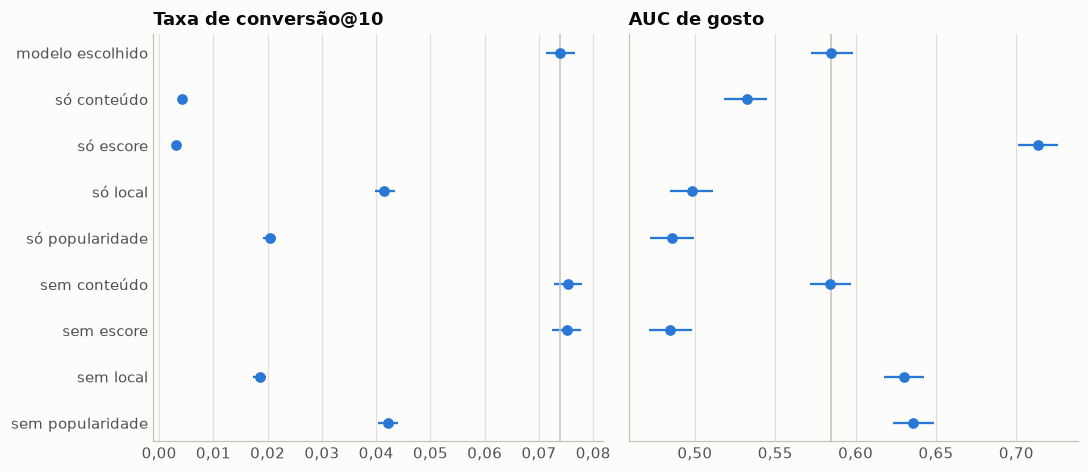

In [12]:
def sem_componente(pesos, indice):
    restantes = [0.0 if i == indice else peso for i, peso in enumerate(pesos)]
    soma = sum(restantes)
    return tuple(peso / soma for peso in restantes)


nomes_componentes = ["conteúdo", "escore", "local", "popularidade"]
casos_ablacao = {"modelo escolhido": pesos_finais}
for i, nome in enumerate(nomes_componentes):
    casos_ablacao[f"só {nome}"] = tuple(1.0 if j == i else 0.0 for j in range(4))
for i, nome in enumerate(nomes_componentes):
    if pesos_finais[i] > 0:
        casos_ablacao[f"sem {nome}"] = sem_componente(pesos_finais, i)
resultados_ablacao = {nome: medir(componentes_atuais, pesos) for nome, pesos in casos_ablacao.items()}
display(tabela_contra_base(resultados_ablacao, "modelo escolhido"))

nomes_casos = list(resultados_ablacao)[::-1]
figura, (eixo_conversao, eixo_gosto) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for eixo, metrica, titulo, casas in [(eixo_conversao, "conversao", "Taxa de conversão@10", 2), (eixo_gosto, "auc_gosto", "AUC de gosto", 2)]:
    medias, inferiores, superiores = zip(*(intervalo(resultados_ablacao[nome], metrica) for nome in nomes_casos))
    medias, inferiores, superiores = np.array(medias), np.array(inferiores), np.array(superiores)
    eixo.errorbar(medias, range(len(nomes_casos)), xerr=[medias - inferiores, superiores - medias], fmt="o", color=COR_PRINCIPAL, markersize=6, capsize=0, elinewidth=1.5)
    eixo.axvline(medias[nomes_casos.index("modelo escolhido")], color=COR_EIXO, linewidth=1)
    eixo.set_title(titulo)
    eixo.grid(axis="y", visible=False)
    eixo_br(eixo.xaxis, casas)
eixo_conversao.set_yticks(range(len(nomes_casos)), nomes_casos)
figura.tight_layout()
salvar(figura, "32_ablacao")
plt.show()

**Ablação:**

- **Local e popularidade respondem pela conversão:** sem local, ela cai para 0,0185; sem popularidade, para 0,0421.
- **O escore responde pelo gosto:** sem ele, a AUC de gosto cai para 0,4847, um valor abaixo de 0,5; sozinho, chega a 0,7136, mas cobre só 1,0% do catálogo e converte 0,0031.
- **A combinação vale mais que as partes:** nenhum componente sozinho passa de 0,0415 de conversão, contra 0,0739 do modelo.
- **O conteúdo não melhora as métricas principais no cenário 1:** sem ele, a conversão é até maior (0,0015, IC 95% de 0,0005 a 0,0024) e a AUC de gosto empata (−0,0007, IC 95% de −0,0061 a 0,0046). A contribuição dele é ampliar o catálogo (45,9% × 40,8%), e o peso de 0,1 é o mínimo exigido. O papel principal do conteúdo está no cenário 3, a ser medido na seção 3.6.

### Sensibilidade

Outros limiares do critério, e usuários com ao menos uma avaliação no treino, em vez de três. Nesse segundo caso, avaliam-se só as combinações que passaram de 90% da melhor conversão na grade principal.

,limiar,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
0,0.90,0.1,0.3,0.4,0.2,0.0696,0.0774,0.6144,0.4073
1,0.95,0.1,0.2,0.5,0.2,0.0739,0.0836,0.5850,0.4595
2,0.97,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004


Fronteira com a configuração final:


,limiar de conversão,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo,conversão cedida,gosto ganho
0,1.00,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004,0.0000,0.0000
1,0.97,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004,0.0000,0.0000
2,0.95,0.1,0.2,0.5,0.2,0.0739,0.0836,0.5850,0.4595,0.0358,0.0418
3,0.90,0.1,0.3,0.4,0.2,0.0696,0.0774,0.6144,0.4073,0.0927,0.0713
4,0.85,0.2,0.3,0.3,0.2,0.0667,0.0742,0.6167,0.4623,0.1300,0.0735
5,0.80,0.1,0.4,0.3,0.2,0.0644,0.0709,0.6411,0.3256,0.1605,0.0980
6,0.70,0.1,0.5,0.3,0.1,0.0538,0.0588,0.6677,0.3538,0.2983,0.1246


Correlação entre conversão e AUC de gosto na grade final: -0,36


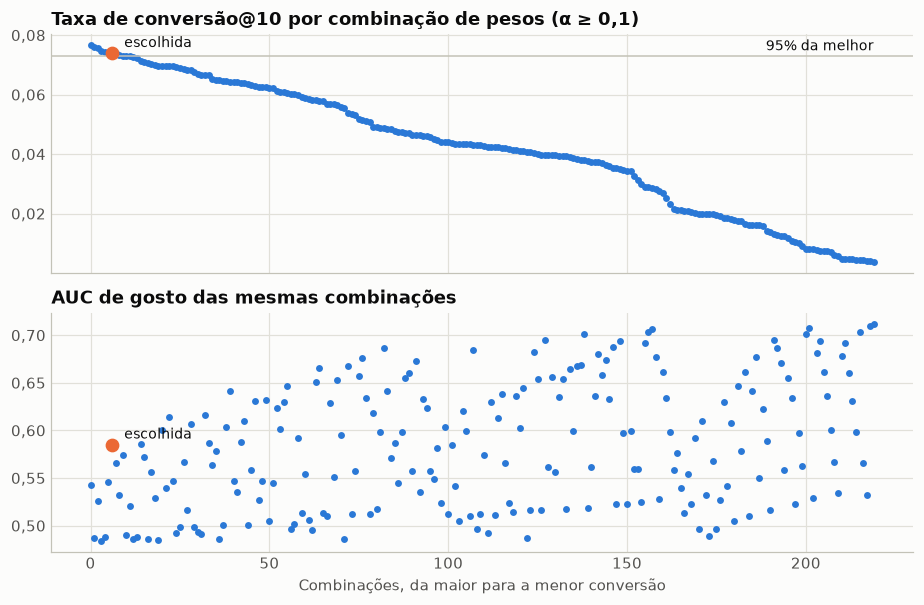

Usuários com 1 ou mais avaliações: 10.000; combinações avaliadas: 25
Escolhida nesse grupo: (0.1, 0.2, 0.5, 0.2), conversão 0,0598, AUC de gosto 0,5783
Pesos do cenário 1 nesse grupo: conversão 0,0598, AUC de gosto 0,5783


In [13]:
grade_final = grade if not mudou_etapa3 else avaliar_grade("etapa2_pesos_final", protocolo_antigo, componentes_atuais, grade_de_pesos(0.1), configuracao)
linhas_limiar = []
for limiar in [0.90, 0.95, 0.97]:
    combinacao = escolher_pesos(grade_final, limiar=limiar)
    linhas_limiar.append({"limiar": limiar} | combinacao[colunas_grade].astype(float).to_dict())
display(pd.DataFrame(linhas_limiar).round(4))

elegiveis_grade_final = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
melhor_final = elegiveis_grade_final.sort_values("conversao", ascending=False).iloc[0]
fronteira_final = pd.DataFrame(
    [{"limiar de conversão": limiar} | escolher_pesos(grade_final, limiar=limiar)[colunas_grade].astype(float).to_dict() for limiar in limiares_fronteira]
)
fronteira_final["conversão cedida"] = 1 - fronteira_final["conversao"] / melhor_final["conversao"]
fronteira_final["gosto ganho"] = fronteira_final["auc_gosto"] - melhor_final["auc_gosto"]
print("Fronteira com a configuração final:")
display(fronteira_final.round(4))
print(f"Correlação entre conversão e AUC de gosto na grade final: {numero_br(elegiveis_grade_final['conversao'].corr(elegiveis_grade_final['auc_gosto']), 2)}")

ordenada = elegiveis_grade_final.sort_values("conversao", ascending=False).reset_index(drop=True)
posicao_escolhida = ordenada.index[(ordenada[NOMES_PESOS].sub(list(pesos_finais)).abs().sum(axis=1) < 1e-9)][0]
figura, (eixo_conversao, eixo_gosto) = plt.subplots(2, 1, figsize=(8.5, 5.6), sharex=True)
eixo_conversao.plot(ordenada.index, ordenada["conversao"], "o", color=COR_PRINCIPAL, markersize=3.5)
eixo_conversao.axhline(0.95 * ordenada["conversao"].max(), color=COR_EIXO, linewidth=1)
eixo_conversao.annotate("95% da melhor", (len(ordenada) - 1, 0.95 * ordenada["conversao"].max()), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=9)
eixo_conversao.plot(posicao_escolhida, ordenada.loc[posicao_escolhida, "conversao"], "o", color=COR_SECUNDARIA, markersize=8)
eixo_conversao.annotate("escolhida", (posicao_escolhida, ordenada.loc[posicao_escolhida, "conversao"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
eixo_conversao.set_title("Taxa de conversão@10 por combinação de pesos (α ≥ 0,1)")
eixo_br(eixo_conversao.yaxis, 2)
eixo_gosto.plot(ordenada.index, ordenada["auc_gosto"], "o", color=COR_PRINCIPAL, markersize=3.5)
eixo_gosto.plot(posicao_escolhida, ordenada.loc[posicao_escolhida, "auc_gosto"], "o", color=COR_SECUNDARIA, markersize=8)
eixo_gosto.annotate("escolhida", (posicao_escolhida, ordenada.loc[posicao_escolhida, "auc_gosto"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
eixo_gosto.set_title("AUC de gosto das mesmas combinações")
eixo_gosto.set_xlabel("Combinações, da maior para a menor conversão")
eixo_br(eixo_gosto.yaxis, 2)
figura.tight_layout()
salvar(figura, "31_grade_pesos")
plt.show()


protocolo_amplo = montar_protocolo(treino, validacao, locais, ["antigo", "intermediario"])
componentes_amplos = calcular_componentes(treino, locais, protocolo_amplo.usuarios, protocolo_amplo.candidatos, **configuracao)
elegiveis_final = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
finalistas_amplos = elegiveis_final[elegiveis_final["conversao"] >= 0.9 * elegiveis_final["conversao"].max()]
combinacoes_amplas = [tuple(float(linha[nome]) for nome in NOMES_PESOS) for _, linha in finalistas_amplos.iterrows()]
grade_ampla = avaliar_grade("sensibilidade_um_ou_mais", protocolo_amplo, componentes_amplos, combinacoes_amplas, configuracao)
print(f"Usuários com 1 ou mais avaliações: {inteiro(len(protocolo_amplo.usuarios))}; combinações avaliadas: {len(grade_ampla)}")
escolha_ampla = escolher_pesos(grade_ampla)
print(f"Escolhida nesse grupo: {tuple(float(escolha_ampla[nome]) for nome in NOMES_PESOS)}, conversão {numero_br(escolha_ampla['conversao'], 4)}, AUC de gosto {numero_br(escolha_ampla['auc_gosto'], 4)}")
linha_final = grade_ampla[grade_ampla[NOMES_PESOS].sub(list(pesos_finais)).abs().sum(axis=1) < 1e-9]
if len(linha_final):
    print(f"Pesos do cenário 1 nesse grupo: conversão {numero_br(linha_final['conversao'].iloc[0], 4)}, AUC de gosto {numero_br(linha_final['auc_gosto'].iloc[0], 4)}")

**Sensibilidade:** com limiar de 90%, os pesos mudam para 0,1 / 0,3 / 0,4 / 0,2 (conversão de 0,0696 e AUC de 0,6144); com 97%, para 0,1 / 0,1 / 0,6 / 0,2 (0,0767 e 0,5431). A escolha depende do limiar, porque conversão e gosto competem (correlação de −0,36 na grade final): cada ganho de gosto custa conversão. Ceder 3,6% da melhor conversão rende 0,0418 de AUC de gosto, e ceder 9,3% rende 0,0713. Com usuários de 1 ou mais avaliações, a amostra de 10.000 escolhe os mesmos pesos (conversão de 0,0598 e AUC de 0,5783), o que indica estabilidade.

### Finalistas

A correlação de rankings é lenta, então só os finalistas a recebem, junto com as demais métricas. Aqui a lista óbvia da serendipidade é popularidade + local, em partes iguais.

In [14]:
elegiveis_f = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
aptas_f = elegiveis_f[elegiveis_f["conversao"] >= 0.95 * elegiveis_f["conversao"].max()].sort_values("auc_gosto", ascending=False).head(4)
finalistas = {f"{tuple(float(linha[n]) for n in NOMES_PESOS)}": tuple(float(linha[n]) for n in NOMES_PESOS) for _, linha in aptas_f.iterrows()}
modelo_obvio = modelo_ponderado(componentes_atuais, (0.0, 0.0, 0.5, 0.5))
vetorizador_final = VetorizadorConteudo(**configuracao.get("opcoes_vetor", {})).fit(locais[locais["gmap_id"].isin(treino["gmap_id"])])
vetores_finais = vetorizador_final.transform(locais.iloc[indice_locais.loc[protocolo_antigo.candidatos]])
tabela_finalistas = pd.DataFrame(
    {
        nome: medir(componentes_atuais, pesos, completo=True, com_correlacao=True, vetores=vetores_finais, modelo_obvio=modelo_obvio).resumo()
        for nome, pesos in finalistas.items()
    }
).round(4)
tabela_finalistas

,"(0.1, 0.2, 0.5, 0.2)","(0.1, 0.1, 0.7, 0.1)","(0.1, 0.2, 0.4, 0.3)","(0.2, 0.1, 0.5, 0.2)"
conversao,0.0739,0.0731,0.0739,0.0741
consumo,0.0836,0.0835,0.0843,0.0861
auc_gosto,0.5850,0.5745,0.5661,0.5458
spearman,0.1200,0.1044,0.0892,0.0663
kendall,0.1024,0.0896,0.0763,0.0561
auc_consumo,0.9167,0.9084,0.9211,0.9163
novidade,9.0859,9.3147,8.8585,9.0752
diversidade,0.6916,0.6939,0.6853,0.6760
serendipidade,0.0236,0.0267,0.0185,0.0234
cobertura_catalogo,0.4595,0.6272,0.3707,0.6018


**Finalistas:** a correlação de rankings confirma a AUC de gosto: a combinação escolhida tem os maiores Spearman (0,1200) e tau-b de Kendall (0,1024). Esses valores são baixos, o que confirma o pouco espaço para prever o gosto. A AUC de consumo fica entre 0,91 e 0,92 em todas, então ela não separa os finalistas, como esperado. Serendipidade, novidade e diversidade variam pouco e servem só de acompanhamento.

## Implementação do recomendador

A classe `Recomendador` reúne os componentes e a configuração congelada. Ela recomenda para usuário com histórico, inclusive com 1 ou 2 avaliações, para usuário novo e para local novo. Os pesos dos cenários 2 e 3 são provisórios aqui e são decididos nas seções seguintes. Nomes de pessoas não aparecem: os exemplos usam "Usuário A".

In [15]:
recomendador = Recomendador(
    pesos=pesos_finais,
    percentil=configuracao["percentil"],
    centro=configuracao["centro"],
    local=configuracao["local"],
    tau=configuracao.get("tau"),
    opcoes_vetor=configuracao.get("opcoes_vetor"),
).ajustar(treino, locais)

amostra_conferencia = protocolo_antigo.usuarios[:200]
pontuacoes_classe = recomendador.pontuar(amostra_conferencia, protocolo_antigo.candidatos)
pontuacoes_etapa = pontuar_componentes(componentes_atuais, pesos_finais)[:200]
print(f"Mesmas pontuações da etapa anterior: {bool(np.allclose(pontuacoes_classe, pontuacoes_etapa))}")

sem_traducao = [nome for nome in recomendador.nomes_tokens if traduzir_token(nome) is None]
print(f"Tokens no vetor: {len(recomendador.nomes_tokens)}; sem tradução: {len(sem_traducao)}")

gerador_exemplo = np.random.default_rng(42)
ativos_exemplo = recomendador.avaliacoes_por_usuario[recomendador.avaliacoes_por_usuario >= 5].index.intersection(protocolo_antigo.usuarios)
usuario_a = gerador_exemplo.choice(np.sort(ativos_exemplo.to_numpy().astype(str)))
inicio = perf_counter()
lista_a = recomendador.recomendar(usuario_a, n=10)
print(f"Tempo de uma lista com explicações: {numero_br(perf_counter() - inicio, 2)} s")

historico_a = treino[treino["user_id"] == usuario_a].merge(locais[["gmap_id", "name", "cidade", "categoria_principal"]], on="gmap_id")
print(f"Usuário A: {len(historico_a)} avaliações no treino")
display(historico_a.sort_values("rating", ascending=False)[["name", "cidade", "categoria_principal", "rating"]].head(8).reset_index(drop=True))
with pd.option_context("display.max_colwidth", 110):
    display(lista_a[["nome", "cidade", "categoria_principal", "pontuacao"]].round(3))
    display(lista_a[["nome", "explicacao"]].head(5))

Mesmas pontuações da etapa anterior: True
Tokens no vetor: 167; sem tradução: 0
Tempo de uma lista com explicações: 0,13 s
Usuário A: 5 avaliações no treino


,name,cidade,categoria_principal,rating
0,Pizza Hut,Cheyenne,Pizza delivery,5
1,R&B Breakfast Club,Cheyenne,Breakfast restaurant,5
2,Applebee's Grill + Bar,Cheyenne,Restaurant,5
3,Chili's Grill & Bar,Cheyenne,Tex-Mex restaurant,5
4,Guadalajara Mexican Restaurant Cheyenne,Cheyenne,Mexican restaurant,4


,nome,cidade,categoria_principal,pontuacao
0,Texas Roadhouse,Cheyenne,Steak house,0.919
1,Chick-fil-A,Cheyenne,Fast food restaurant,0.915
2,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.906
3,2 Doors Down,Cheyenne,American restaurant,0.903
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.901
5,Wasabi,Cheyenne,Sushi restaurant,0.894
6,Culver's,Cheyenne,American restaurant,0.888
7,Anong's | Thai Cuisine,Cheyenne,Thai restaurant,0.881
8,Paramount Cafe,Cheyenne,Coffee shop,0.880
9,Olive Garden Italian Restaurant,Cheyenne,Italian restaurant,0.879


,nome,explicacao
0,Texas Roadhouse,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Restaurante americano, Chu..."
1,Chick-fil-A,"Porque você gostou de R&B Breakfast Club (nota 5). Em comum com seu perfil: Café da manhã, Restaurante fam..."
2,"Wyoming's Rib & Chop House, Cheyenne","Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Churrascaria, Restaurante ..."
3,2 Doors Down,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar no local, Hamburgueria..."
4,Sanford's Grub & Pub,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar e grill, Refeição no l..."


In [16]:
amostra_explicacoes = gerador_exemplo.choice(protocolo_antigo.usuarios, size=100, replace=False)
com_parecido, quantidade_tokens, avaliados_na_lista, fechados_na_lista = [], [], 0, 0
fechados_ids = set(locais.loc[locais["fechado_perm"] | locais["fechado_temp"], "gmap_id"])
for usuario in amostra_explicacoes:
    lista = recomendador.recomendar(usuario, n=10, com_explicacao=False)
    avaliados_usuario = set(treino.loc[treino["user_id"] == usuario, "gmap_id"])
    avaliados_na_lista += len(set(lista["gmap_id"]) & avaliados_usuario)
    fechados_na_lista += len(set(lista["gmap_id"]) & fechados_ids)
    for gmap_id in lista["gmap_id"]:
        explicacao = recomendador.explicar(usuario, gmap_id)
        com_parecido.append(explicacao["parecido"] is not None)
        quantidade_tokens.append(len(explicacao["tokens"]))
print(f"Em 100 usuários e 1.000 recomendações:")
print(f"  com local parecido na explicação: {numero_br(100 * np.mean(com_parecido), 1)}%")
print(f"  tokens por explicação: média {numero_br(np.mean(quantidade_tokens), 2)}")
print(f"  já avaliados na lista: {avaliados_na_lista}; fechados na lista: {fechados_na_lista}")

previsoes_a = recomendador.prever_nota([usuario_a] * 3, lista_a["gmap_id"].head(3).tolist())
print(f"Nota prevista para os 3 primeiros do Usuário A: {[numero_br(valor, 2) for valor in previsoes_a]}")

print("Usuário novo em Cheyenne, com café como preferência (pesos provisórios):")
display(recomendador.recomendar_usuario_novo(cidade="Cheyenne", categorias=["Coffee shop"], n=5)[["nome", "cidade", "categoria_principal", "pontuacao"]].round(3))

novos_naturais = pd.read_parquet(PASTA_CONJUNTOS / "locais_novos.parquet").query("origem == 'natural' and conjunto == 'validacao'")
cadastro_real = locais[locais["gmap_id"].isin(novos_naturais["gmap_id"]) & ~locais["fechado_perm"] & ~locais["fechado_temp"]].iloc[0].to_dict()
print(f"Local novo real: {cadastro_real['name']} ({cadastro_real['cidade']}, {cadastro_real['categoria_principal']}), tratado como cadastro (pesos provisórios)")
print(recomendador.posicao_local_novo(usuario_a, cadastro_real, n=10))
inicio = perf_counter()
tabela_novos = recomendador.usuarios_para_local_novo(cadastro_real, n=5)
print(f"Tempo para ordenar os usuários antigos: {numero_br(perf_counter() - inicio, 2)} s")
tabela_novos.drop(columns="user_id").assign(usuario=[f"Usuário #{i + 1}" for i in range(len(tabela_novos))]).round(3)

Em 100 usuários e 1.000 recomendações:
  com local parecido na explicação: 99,0%
  tokens por explicação: média 2,84
  já avaliados na lista: 0; fechados na lista: 0
Nota prevista para os 3 primeiros do Usuário A: ['4,70', '4,83', '4,61']
Usuário novo em Cheyenne, com café como preferência (pesos provisórios):


,nome,cidade,categoria_principal,pontuacao
0,Texas Roadhouse,Cheyenne,Steak house,0.916
1,Chick-fil-A,Cheyenne,Fast food restaurant,0.913
2,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.912
3,2 Doors Down,Cheyenne,American restaurant,0.908
4,Paramount Cafe,Cheyenne,Coffee shop,0.904


Local novo real: Jackson Lake Lodge Pool Dining and BBQ (Moran, Family restaurant), tratado como cadastro (pesos provisórios)
{'posicao': 1342, 'total': 1415, 'recomendar': False, 'pontuacao': 0.31803617612416846}


Tempo para ordenar os usuários antigos: 0,12 s


,pontuacao,conteudo,local,usuario
0,0.498,0.638,0.867,Usuário #1
1,0.494,0.635,0.861,Usuário #2
2,0.489,0.621,0.853,Usuário #3
3,0.488,0.683,0.840,Usuário #4
4,0.486,0.747,0.822,Usuário #5


**Leitura:** a classe dá exatamente as mesmas pontuações da etapa anterior, os 167 tokens do vetor têm tradução, e uma lista com explicações leva 0,13 s. Em 100 usuários e 1.000 recomendações, nenhum local fechado ou já avaliado entrou na lista, e 99,0% das explicações têm um local parecido.

**Duas limitações visíveis nos exemplos:**

- **A lista é pouco pessoal:** o Usuário A, de Cheyenne, recebe sobretudo os locais populares e bem avaliados da cidade dele. Isso é coerente com a ablação: local e popularidade respondem pela conversão, e o conteúdo tem peso de 0,1.
- **A explicação é uma justificativa, não a causa:** "porque você gostou de X" aponta o local mais parecido, mas o que mais pesa na posição é o local e a popularidade. Por isso, a interface mostra também as barras dos componentes, como o plano prevê.

Na lista do usuário novo, a preferência por café quase não muda o resultado com os pesos provisórios; a seção seguinte decide esses pesos. Um local novo real em Moran ficou em 1.342º de 1.415 para um usuário de Cheyenne, o que é coerente com a distância. A seção do cenário 3 mede isso em todos os casos.